[λ=0] Epoch 1, Loss=673.48, Sparsity=35.14%
[λ=0] Epoch 2, Loss=569.09, Sparsity=35.42%
[λ=0] Epoch 3, Loss=514.45, Sparsity=35.69%
[λ=0] Epoch 4, Loss=468.90, Sparsity=35.93%
[λ=0] Epoch 5, Loss=429.27, Sparsity=36.16%
[λ=0] Epoch 6, Loss=390.82, Sparsity=36.38%
[λ=0] Epoch 7, Loss=351.34, Sparsity=36.60%
[λ=0] Epoch 8, Loss=312.92, Sparsity=36.81%
[λ=0] Epoch 9, Loss=275.64, Sparsity=37.01%
[λ=0] Epoch 10, Loss=239.59, Sparsity=37.21%
[λ=0] Epoch 11, Loss=204.98, Sparsity=37.40%
[λ=0] Epoch 12, Loss=176.50, Sparsity=37.58%
[λ=0] Epoch 13, Loss=152.84, Sparsity=37.76%
[λ=0] Epoch 14, Loss=127.69, Sparsity=37.93%
[λ=0] Epoch 15, Loss=112.62, Sparsity=38.09%
[λ=0] Epoch 16, Loss=102.97, Sparsity=38.26%
[λ=0] Epoch 17, Loss=86.61, Sparsity=38.41%
[λ=0] Epoch 18, Loss=83.49, Sparsity=38.58%
[λ=0] Epoch 19, Loss=76.84, Sparsity=38.74%
[λ=0] Epoch 20, Loss=71.83, Sparsity=38.90%
[λ=0] Epoch 21, Loss=61.13, Sparsity=39.04%
[λ=0] Epoch 22, Loss=62.20, Sparsity=39.21%
[λ=0] Epoch 23, Loss=59.1

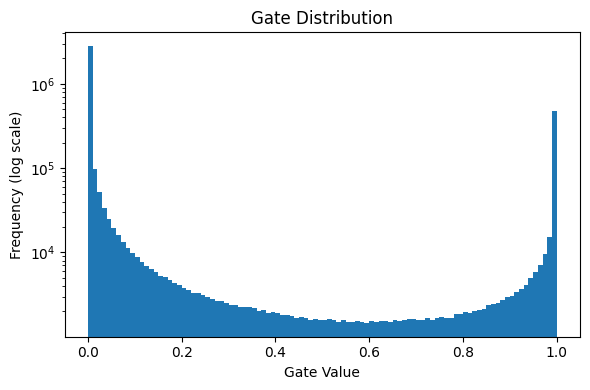

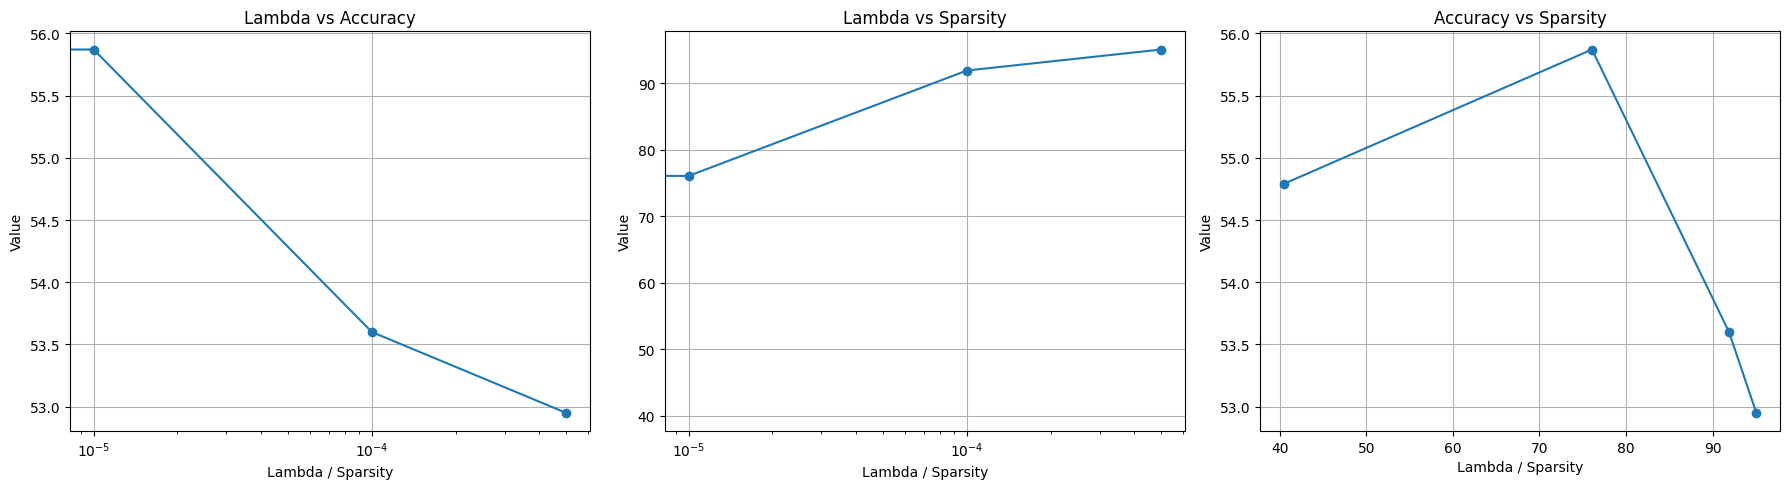

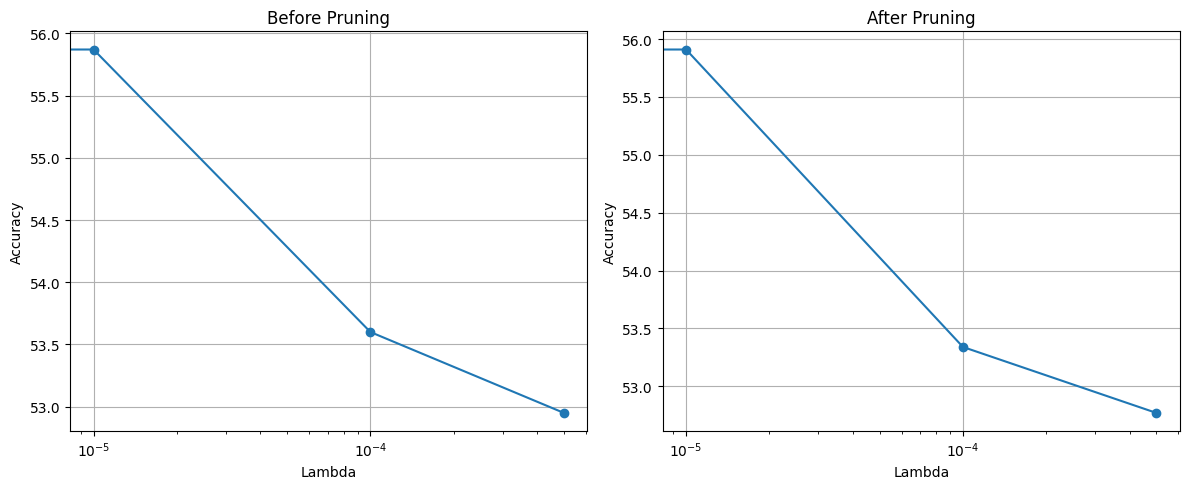

In [3]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

device = "mps" if torch.mps.is_available() else "cpu"

# ----------------------------
# Prunable Linear Layer
# ----------------------------
class PrunableLinear(nn.Module):
    def __init__(self, in_features, out_features, temperature=0.1):
        super().__init__()

        self.weight = nn.Parameter(torch.randn(out_features, in_features) * 0.01)
        self.bias = nn.Parameter(torch.zeros(out_features))

        self.gate_scores = nn.Parameter(torch.randn(out_features, in_features))
        self.temperature = temperature

    def forward(self, x):
        gates = torch.sigmoid(self.gate_scores / self.temperature)
        pruned_weights = self.weight * gates
        return F.linear(x, pruned_weights, self.bias)

    def get_gate_values(self):
        return torch.sigmoid(self.gate_scores / self.temperature)


# ----------------------------
# Model
# ----------------------------
class PrunableMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = PrunableLinear(32*32*3, 1024)
        self.fc2 = PrunableLinear(1024, 512)
        self.fc3 = PrunableLinear(512, 256)
        self.fc4 = PrunableLinear(256, 10)

    def forward(self, x):
        x = x.view(x.size(0), -1)
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = F.relu(self.fc3(x))
        return self.fc4(x)

    def sparsity_loss(self):
        loss = 0
        for m in self.modules():
            if isinstance(m, PrunableLinear):
                loss += m.get_gate_values().sum()
        return loss

    def compute_sparsity(self, threshold=0.02):
        total, pruned = 0, 0
        for m in self.modules():
            if isinstance(m, PrunableLinear):
                gates = m.get_gate_values()
                total += gates.numel()
                pruned += (gates < threshold).sum().item()
        return 100 * pruned / total


# ----------------------------
# Utility Functions
# ----------------------------
def evaluate(model, loader):
    model.eval()
    correct, total = 0, 0

    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            outputs = model(x)
            _, pred = torch.max(outputs, 1)
            total += y.size(0)
            correct += (pred == y).sum().item()

    return 100 * correct / total


def prune_model(model, threshold=0.02):
    for m in model.modules():
        if isinstance(m, PrunableLinear):
            gates = torch.sigmoid(m.gate_scores / m.temperature)
            mask = (gates > threshold).float()
            m.weight.data *= mask


# ----------------------------
# Visualization
# ----------------------------
def plot_gate_distribution(model):
    gates = []

    for m in model.modules():
        if isinstance(m, PrunableLinear):
            gates.extend(m.get_gate_values().detach().cpu().numpy().flatten())

    plt.figure(figsize=(6,4))
    plt.hist(gates, bins=100, log=True)
    plt.title("Gate Distribution")
    plt.xlabel("Gate Value")
    plt.ylabel("Frequency (log scale)")
    plt.tight_layout()
    plt.savefig("gate_distribution.png", dpi=300)
    plt.show()
    plt.close()


def plot_lambda_results(results):
    lambdas = [r[0] for r in results]
    accuracies = [r[1] for r in results]
    sparsities = [r[2] for r in results]

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    axes[0].plot(lambdas, accuracies, marker='o')
    axes[0].set_xscale('log')
    axes[0].set_title("Lambda vs Accuracy")

    axes[1].plot(lambdas, sparsities, marker='o')
    axes[1].set_xscale('log')
    axes[1].set_title("Lambda vs Sparsity")

    axes[2].plot(sparsities, accuracies, marker='o')
    axes[2].set_title("Accuracy vs Sparsity")

    for ax in axes:
        ax.set_xlabel("Lambda / Sparsity")
        ax.set_ylabel("Value")
        ax.grid()

    plt.tight_layout()
    plt.savefig("lambda_analysis.png", dpi=300)
    plt.show()
    plt.close()


def plot_pruning_effect(pruned_results):
    lambdas = [r[0] for r in pruned_results]
    before = [r[1] for r in pruned_results]
    after = [r[2] for r in pruned_results]

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    axes[0].plot(lambdas, before, marker='o')
    axes[0].set_xscale('log')
    axes[0].set_title("Before Pruning")

    axes[1].plot(lambdas, after, marker='o')
    axes[1].set_xscale('log')
    axes[1].set_title("After Pruning")

    for ax in axes:
        ax.set_xlabel("Lambda")
        ax.set_ylabel("Accuracy")
        ax.grid()

    plt.tight_layout()
    plt.savefig("pruning_effect.png", dpi=300)
    plt.show()
    plt.close()


# ----------------------------
# Data
# ----------------------------
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

trainset = torchvision.datasets.CIFAR10("./data", train=True, download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=128, shuffle=True)

testset = torchvision.datasets.CIFAR10("./data", train=False, download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=128, shuffle=False)


# ----------------------------
# Training
# ----------------------------
def train_model(lambda_sparse):
    model = PrunableMLP().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    criterion = nn.CrossEntropyLoss()

    num_epochs = 30

    for epoch in range(num_epochs):
        model.train()
        total_loss = 0

        for x, y in trainloader:
            x, y = x.to(device), y.to(device)

            optimizer.zero_grad()

            outputs = model(x)
            ce_loss = criterion(outputs, y)
            sparsity_loss = model.sparsity_loss()

         
            if epoch < 5:
                loss = ce_loss
            else:
                progress = (epoch - 5) / (num_epochs - 5)
                current_lambda = lambda_sparse * progress
                loss = ce_loss + current_lambda * sparsity_loss

            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        print(f"[λ={lambda_sparse}] Epoch {epoch+1}, Loss={total_loss:.2f}, Sparsity={model.compute_sparsity():.2f}%")

    acc = evaluate(model, testloader)
    sparsity = model.compute_sparsity()

    return model, acc, sparsity


# ----------------------------
# Experiments
# ----------------------------
lambda_values = [0, 1e-5, 1e-4, 5e-4]

models = []
results = []
pruned_results = []

for lam in lambda_values:
    model, acc, sparsity = train_model(lam)

    results.append((lam, acc, sparsity))
    models.append(model)

    before_acc = acc
    prune_model(model)
    after_acc = evaluate(model, testloader)

    pruned_results.append((lam, before_acc, after_acc))


# ----------------------------
# Outputs
# ----------------------------
print("\nFinal Results:")
for r in results:
    print(f"Lambda: {r[0]}, Accuracy: {r[1]:.2f}%, Sparsity: {r[2]:.2f}%")

best_idx = max(range(len(results)), key=lambda i: results[i][1])
best_model = models[best_idx]

# ----------------------------
# Plots
# ----------------------------
plot_gate_distribution(best_model)
plot_lambda_results(results)
plot_pruning_effect(pruned_results)

In [1]:
def evaluate(model, loader):
    model.eval()
    correct, total = 0, 0
     with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)

            outputs = model(x)
            _, pred = torch.max(outputs, 1)

            total += y.size(0)
            correct += (pred == y).sum().item()

    return 100 * correct / total

IndentationError: unexpected indent (631487280.py, line 4)

In [5]:
test_results = []

for i, model in enumerate(models):
    acc = evaluate(model, testloader)

    test_results.append((lambda_values[i], acc))

    print(f"Lambda: {lambda_values[i]}, Test Accuracy: {acc:.2f}%")

Lambda: 0, Test Accuracy: 54.77%
Lambda: 1e-05, Test Accuracy: 55.91%
Lambda: 0.0001, Test Accuracy: 53.34%
Lambda: 0.0005, Test Accuracy: 52.77%
